In [25]:
from pathlib import Path

import pandas as pd
import yaml


repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / ".git").exists()
)

experiment_paths = {
    "LoRA - BUSI": "configs/experiment/sam3_lora_busi_full.yaml",
    "Full - BUSI": "configs/experiment/sam3_full_busi_full.yaml",
    "LoRA - Kvasir": "configs/experiment/sam3_lora_kvasir_full.yaml",
    "Full - Kvasir": "configs/experiment/sam3_full_kvasir_full.yaml",
}

experiment_rows = []

for experiment, relative_path in experiment_paths.items():
    config_path = repository_root / relative_path

    with open(config_path, encoding="utf-8") as config_file:
        config = yaml.safe_load(config_file)

    experiment_rows.append(
        {
            "experiment": experiment,
            "dataset": config["data"]["name"],
            "mode": config["model"]["finetune_mode"],
            "training_images": (
                "full"
                if config["data"]["n_train"] is None
                else config["data"]["n_train"]
            ),
            "batch_size": config["data"]["batch_size"],
            "augmentation": config["data"]["aug_preset"],
            "epochs": config["train"]["epochs"],
            "backbone_lr": config["train"]["backbone_lr"],
            "head_lr": config["train"]["head_lr"],
        }
    )

experiment_summary = pd.DataFrame(experiment_rows)
experiment_summary

,experiment,dataset,mode,training_images,batch_size,augmentation,epochs,backbone_lr,head_lr
0,LoRA - BUSI,busi,lora,full,1,medseg_default,20,0.00010,0.0001
1,Full - BUSI,busi,full,full,1,medseg_default,20,0.00001,0.0001
2,LoRA - Kvasir,kvasir,lora,full,1,medseg_default,20,0.00010,0.0001
3,Full - Kvasir,kvasir,full,full,1,medseg_default,20,0.00001,0.0001


In [26]:

import ast
import re


smoke_log_path = (
    repository_root / "slurm_outs" / "slurm_5542448.out"
)
smoke_log = smoke_log_path.read_text(
    encoding="utf-8",
    errors="replace",
)

splits = ast.literal_eval(
    re.search(r"splits: (\{.+?\})", smoke_log).group(1)
)
parameter_match = re.search(
    r"parameters: ([\d,]+) trainable / ([\d,]+) total "
    r"\(([\d.]+)%\)",
    smoke_log,
)
epoch_matches = re.finditer(
    r"epoch (\d+): "
    r"train_loss=([\d.]+)\s+"
    r"val_dice=([\d.]+)\s+"
    r"val_nsd=([\d.]+)",
    smoke_log,
)

smoke_summary = pd.Series(
    {
        "job_id": re.search(
            r"Job ID:\s+(\d+)", smoke_log
        ).group(1),
        "gpu": (
            "NVIDIA H100 80 GB"
            if "NVIDIA H100 80GB" in smoke_log
            else "not detected"
        ),
        "train_images": splits["train"],
        "validation_images": splits["val"],
        "test_images": splits["test"],
        "trainable_parameters": parameter_match.group(1),
        "total_parameters": parameter_match.group(2),
        "trainable_percent": float(parameter_match.group(3)),
        "peak_vram_gb": float(
            re.search(
                r"peak_vram=([\d.]+)GB",
                smoke_log,
            ).group(1)
        ),
        "walltime": re.search(
            r"walltime=([\d:]+)",
            smoke_log,
        ).group(1),
        "completed": (
            "done" in smoke_log
            and "Begin Slurm Epilog" in smoke_log
        ),
    },
    name="value",
)

smoke_epochs = pd.DataFrame(
    [
        {
            "epoch": int(match.group(1)),
            "train_loss": float(match.group(2)),
            "val_dice": float(match.group(3)),
            "val_nsd": float(match.group(4)),
        }
        for match in epoch_matches
    ]
)

display(smoke_summary.to_frame())
display(smoke_epochs)

,value
job_id,5542448
gpu,NVIDIA H100 80 GB
train_images,8
validation_images,64
test_images,131
trainable_parameters,"454,581,633"
total_parameters,"454,581,633"
trainable_percent,100.0
peak_vram_gb,9.4
walltime,00:02:58


,epoch,train_loss,val_dice,val_nsd
0,1,1.2893,0.5033,0.0567
1,2,0.7517,0.5939,0.0735


In [27]:
H100_MEMORY_GB = 80.0
EXPECTED_TRAINABLE_PERCENT = 100.0

first_epoch = smoke_epochs.iloc[0]
last_epoch = smoke_epochs.iloc[-1]

validation_checks = pd.Series(
    {
        "job_completed": bool(smoke_summary["completed"]),
        "all_parameters_trainable": (
            float(smoke_summary["trainable_percent"])
            == EXPECTED_TRAINABLE_PERCENT
        ),
        "training_loss_decreased": (
            last_epoch["train_loss"]
            < first_epoch["train_loss"]
        ),
        "validation_dice_improved": (
            last_epoch["val_dice"]
            > first_epoch["val_dice"]
        ),
        "fits_in_h100_memory": (
            float(smoke_summary["peak_vram_gb"])
            < H100_MEMORY_GB
        ),
    },
    name="passed",
)

display(validation_checks.to_frame())

assert validation_checks.all(), "Smoke validation failed"

loss_reduction = (
    first_epoch["train_loss"]
    - last_epoch["train_loss"]
)
dice_improvement = (
    last_epoch["val_dice"]
    - first_epoch["val_dice"]
)

print(f"Loss reduction: {loss_reduction:.4f}")
print(f"Validation Dice improvement: {dice_improvement:.4f}")

,passed
job_completed,True
all_parameters_trainable,True
training_loss_decreased,True
validation_dice_improved,True
fits_in_h100_memory,True


Loss reduction: 0.5376
Validation Dice improvement: 0.0906


In [ ]:
import subprocess


busi_config = (
    "configs/experiment/sam3_full_busi_full.yaml"
)
busi_command = [
    "sbatch",
    "scripts/train_full.sbatch",
    busi_config,
]

# Change to True only when intentionally submitting this job.
SUBMIT_BUSI_JOB = False #True

if SUBMIT_BUSI_JOB:
    submission = subprocess.run(
        busi_command,
        cwd="/home/hice1/skang411/group_project",
        capture_output=True,
        text=True,
        check=True,
    )
    print(submission.stdout.strip())
else:
    print("Submission disabled.")
    print("Command:", " ".join(busi_command))

Submitted batch job 5542554


In [ ]:
BUSI_JOB_ID = "5542554"

!squeue -j {BUSI_JOB_ID} -o "%.18i %.12P %.16j %.2t %.10M %R"

             JOBID    PARTITION             NAME ST       TIME NODELIST(REASON)
           5542554      ice-gpu        sam3_full  R       1:23 atl1-1-03-012-18-0


In [12]:
!tail -n 12 /home/hice1/skang411/group_project/slurm_outs/slurm_5542554.out

---------------------------------------
Begin Slurm Epilog: Jul-27-2026 16:22:46
Job ID:        5542554
User ID:       skang411
Account:       isye
Job name:      sam3_full
Resources:     cpu=8,gres/gpu:h100=1,mem=32G,node=1
Rsrc Used:     cput=05:06:16,vmem=0,walltime=00:38:17,mem=8734532K,energy_used=0
Partition:     ice-gpu
QOS:           coc-ice
Nodes:         atl1-1-03-012-18-0
---------------------------------------


In [7]:
import subprocess


kvasir_command = [
    "sbatch",
    "scripts/train_full.sbatch",
    "configs/experiment/sam3_full_kvasir_full.yaml",
]

# Change to True only for the intentional one-time submission.
SUBMIT_KVASIR_JOB = True

if SUBMIT_KVASIR_JOB:
    submission = subprocess.run(
        kvasir_command,
        cwd="/home/hice1/skang411/group_project",
        capture_output=True,
        text=True,
        check=True,
    )
    print(submission.stdout.strip())
else:
    print("Submission disabled.")
    print("Command:", " ".join(kvasir_command))

Submitted batch job 5542685


In [28]:
BUSI_JOB_ID = "5542685"

!squeue -j {BUSI_JOB_ID} -o "%.18i %.12P %.16j %.2t %.10M %R"

             JOBID    PARTITION             NAME ST       TIME NODELIST(REASON)
           5542685      ice-gpu        sam3_full  R      31:29 atl1-1-03-012-18-0


In [40]:
!tail -n 12 /home/hice1/skang411/group_project/slurm_outs/slurm_5542685.out

---------------------------------------
Begin Slurm Epilog: Jul-27-2026 17:19:34
Job ID:        5542685
User ID:       skang411
Account:       isye
Job name:      sam3_full
Resources:     cpu=8,gres/gpu:h100=1,mem=32G,node=1
Rsrc Used:     cput=07:50:16,vmem=0,walltime=00:58:47,mem=8894636K,energy_used=0
Partition:     ice-gpu
QOS:           coc-ice
Nodes:         atl1-1-03-012-18-0
---------------------------------------


## BUSI Results

In [15]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


BUSI_JOB_ID = "5542554"
busi_log_path = Path(
    f"/home/hice1/skang411/group_project/"
    f"slurm_outs/slurm_{BUSI_JOB_ID}.out"
)
busi_log = busi_log_path.read_text(
    encoding="utf-8",
    errors="replace",
)

epoch_pattern = re.compile(
    r"epoch (\d+): "
    r"train_loss=([\d.]+)\s+"
    r"val_dice=([\d.]+)\s+"
    r"val_nsd=([\d.]+)"
)

busi_epochs = pd.DataFrame(
    [
        {
            "epoch": int(match.group(1)),
            "train_loss": float(match.group(2)),
            "val_dice": float(match.group(3)),
            "val_nsd": float(match.group(4)),
        }
        for match in epoch_pattern.finditer(busi_log)
    ]
)

if busi_epochs.empty:
    raise ValueError("No epoch results found in the BUSI log")

best_dice_row = busi_epochs.loc[
    busi_epochs["val_dice"].idxmax()
]
best_nsd_row = busi_epochs.loc[
    busi_epochs["val_nsd"].idxmax()
]
final_row = busi_epochs.iloc[-1]

loss_reduction_percent = (
    (
        busi_epochs.iloc[0]["train_loss"]
        - final_row["train_loss"]
    )
    / busi_epochs.iloc[0]["train_loss"]
    * 100
)

peak_vram_match = re.search(
    r"peak_vram=([\d.]+)GB",
    busi_log,
)
walltime_match = re.search(
    r"walltime=([\d:]+)",
    busi_log,
)

busi_summary = pd.Series(
    {
        "job_id": BUSI_JOB_ID,
        "epochs_completed": len(busi_epochs),
        "best_validation_dice": best_dice_row["val_dice"],
        "best_dice_epoch": int(best_dice_row["epoch"]),
        "final_validation_dice": final_row["val_dice"],
        "best_validation_nsd": best_nsd_row["val_nsd"],
        "best_nsd_epoch": int(best_nsd_row["epoch"]),
        "final_training_loss": final_row["train_loss"],
        "training_loss_reduction_percent": loss_reduction_percent,
        "peak_vram_gb": (
            float(peak_vram_match.group(1))
            if peak_vram_match
            else None
        ),
        "walltime": (
            walltime_match.group(1)
            if walltime_match
            else None
        ),
        "completed": (
            "done" in busi_log
            and "Begin Slurm Epilog" in busi_log
        ),
    },
    name="value",
)

display(busi_summary.to_frame())
display(
    busi_epochs.style.format(
        {
            "train_loss": "{:.4f}",
            "val_dice": "{:.4f}",
            "val_nsd": "{:.4f}",
        }
    )
)

,value
job_id,5542554
epochs_completed,20
best_validation_dice,0.7885
best_dice_epoch,9
final_validation_dice,0.766
best_validation_nsd,0.2396
best_nsd_epoch,16
final_training_loss,0.1894
training_loss_reduction_percent,70.026903
peak_vram_gb,9.4


,epoch,train_loss,val_dice,val_nsd
0,1,0.6319,0.7470,0.2157
1,2,0.4456,0.7773,0.2156
2,3,0.3721,0.7739,0.2095
3,4,0.3419,0.7232,0.2217
4,5,0.3029,0.7369,0.1333
5,6,0.2784,0.7554,0.2173
6,7,0.2989,0.7327,0.1777
7,8,0.2664,0.7633,0.2225
8,9,0.2641,0.7885,0.2257
9,10,0.2204,0.7791,0.2247


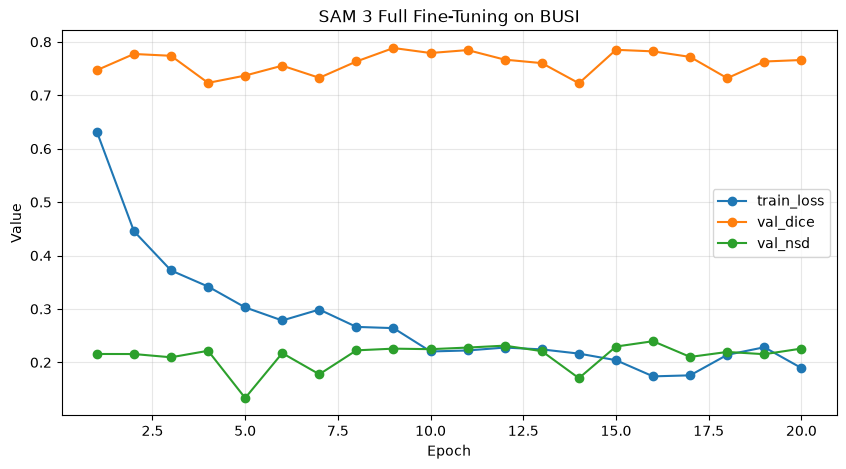

In [20]:
%matplotlib inline

ax = busi_epochs.plot(
    x="epoch",
    y=["train_loss", "val_dice", "val_nsd"],
    marker="o",
    figsize=(10, 5),
)

ax.set_title("SAM 3 Full Fine-Tuning on BUSI")
ax.set_xlabel("Epoch")
ax.set_ylabel("Value")
ax.grid(alpha=0.3)

plt.show()

- Training loss decreased by 70.0%, from 0.6319 to 0.1894.
- The best validation Dice was 0.7885 at epoch 9.
- Validation Dice ended at 0.7660, which is 0.0225 below the best checkpoint.
- The best validation NSD was 0.2396 at epoch 16.
- Peak GPU memory was 9.4 GB.

Training loss continued decreasing after the best Dice epoch, while validation Dice fluctuated without setting a new maximum. This suggests diminishing validation benefit and possible mild overfitting after epoch 9. Saving the best-validation checkpoint was therefore important.

The checkpoint was selected using validation Dice, consistent with the existing LoRA protocol. Test-set performance has not yet been evaluated.

## KVASIR Results

,epoch,train_loss,val_dice,val_nsd
0,1,0.3735,0.8561,0.2370
1,2,0.2414,0.8883,0.3484
2,3,0.1854,0.9039,0.3596
3,4,0.1516,0.9139,0.4249
4,5,0.1841,0.9132,0.3970
5,6,0.1454,0.9093,0.4001
6,7,0.1229,0.8968,0.3755
7,8,0.1269,0.9070,0.3951
8,9,0.1324,0.9033,0.3631
9,10,0.1129,0.9310,0.4289


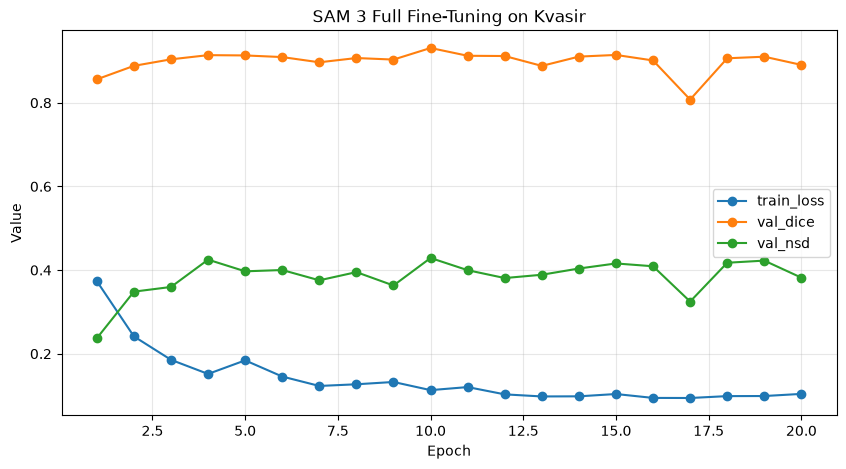

In [41]:
KVASIR_JOB_ID = "5542685"

kvasir_log_path = Path(
    f"/home/hice1/skang411/group_project/"
    f"slurm_outs/slurm_{KVASIR_JOB_ID}.out"
)
kvasir_log = kvasir_log_path.read_text(
    encoding="utf-8",
    errors="replace",
)

kvasir_epochs = pd.DataFrame(
    [
        {
            "epoch": int(match.group(1)),
            "train_loss": float(match.group(2)),
            "val_dice": float(match.group(3)),
            "val_nsd": float(match.group(4)),
        }
        for match in epoch_pattern.finditer(kvasir_log)
    ]
)

display(kvasir_epochs)

ax = kvasir_epochs.plot(
    x="epoch",
    y=["train_loss", "val_dice", "val_nsd"],
    marker="o",
    figsize=(10, 5),
)

ax.set_title("SAM 3 Full Fine-Tuning on Kvasir")
ax.set_xlabel("Epoch")
ax.set_ylabel("Value")
ax.grid(alpha=0.3)

plt.show()

In [42]:
full_results = []

for dataset, job_id, results in [
    ("BUSI", BUSI_JOB_ID, busi_epochs),
    ("Kvasir", KVASIR_JOB_ID, kvasir_epochs),
]:
    best_dice = results.loc[results["val_dice"].idxmax()]
    best_nsd = results.loc[results["val_nsd"].idxmax()]
    first_epoch = results.iloc[0]
    final_epoch = results.iloc[-1]

    full_results.append(
        {
            "dataset": dataset,
            "job_id": job_id,
            "best_val_dice": best_dice["val_dice"],
            "best_dice_epoch": int(best_dice["epoch"]),
            "final_val_dice": final_epoch["val_dice"],
            "best_val_nsd": best_nsd["val_nsd"],
            "best_nsd_epoch": int(best_nsd["epoch"]),
            "loss_reduction_percent": (
                (
                    first_epoch["train_loss"]
                    - final_epoch["train_loss"]
                )
                / first_epoch["train_loss"]
                * 100
            ),
        }
    )

full_results = pd.DataFrame(full_results)

display(
    full_results.style.format(
        {
            "best_val_dice": "{:.4f}",
            "final_val_dice": "{:.4f}",
            "best_val_nsd": "{:.4f}",
            "loss_reduction_percent": "{:.1f}%",
        }
    )
)

,dataset,job_id,best_val_dice,best_dice_epoch,final_val_dice,best_val_nsd,best_nsd_epoch,loss_reduction_percent
0,BUSI,5542685,0.7885,9,0.7660,0.2396,16,70.0%
1,Kvasir,5542685,0.9310,10,0.8906,0.4289,10,72.2%


- Training loss (blue): drops 0.3735 → 0.1039 (~72%), then plateaus.
- Validation Dice (orange): improves quickly and peaks at 0.9310 on epoch 10.
- Validation NSD (green): also peaks at epoch 10 (0.4289).

Epoch 10 is the clear checkpoint choice because both overlap and boundary metrics peak together. The epoch-17 drop recovers immediately, suggesting validation/augmentation variability rather than permanent model collapse.